# IMDB Sentiment Classification with Recurrent Neural Networks (RNN)

## About the IMDB Dataset

The **IMDB Large Movie Review Dataset** is a benchmark collection of 50,000 highly polarized movie reviews from the Internet Movie Database (IMDb), labeled for binary sentiment classification (positive or negative). It is evenly split into 25,000 reviews for training and 25,000 reviews for testing, with an equal balance of 12,500 positive and 12,500 negative reviews in each set.

### History
- **Origins (2011):** The dataset was curated and introduced by Andrew L. Maas, Raymond E. Daly, Peter T. Pham, Dan Huang, Andrew Y. Ng, and Christopher Potts from Stanford University in their seminal paper *"Learning Word Vectors for Sentiment Analysis"* (ACL 2011).
- **Filling a Data Void:** Prior to this dataset, sentiment analysis benchmarks (such as the Cornell Movie Review dataset by Pang & Lee) contained only 1,000 to 2,000 labeled reviews, which severely restricted researchers from training expressive statistical and neural models without immediately overfitting.
- **Labeling Methodology:** To ensure clean polarity, reviews were collected with their corresponding 1–10 star ratings:
  - **Negative (<= 4 stars):** Labeled as `0`.
  - **Positive (>= 7 stars):** Labeled as `1`.
  - **Neutral (5–6 stars):** Discarded to prevent ambiguous sentiment.
- **Bias Prevention:** To avoid author or movie bias, no more than 30 reviews were sampled from any single movie.

### Importance in AI
- **The "MNIST of Natural Language Processing":** Much like MNIST established the standard testing ground for computer vision, IMDB became the gold-standard benchmark for text classification and sentiment analysis throughout the 2010s.
- **The Crucible for Sequence Models:** As deep learning expanded into NLP, IMDB proved that sequential neural networks—specifically Recurrent Neural Networks (**SimpleRNN**), Long Short-Term Memory networks (**LSTM**), and Gated Recurrent Units (**GRU**)—could decisively outperform classical Bag-of-Words (BoW) and $n$-gram linear classifiers by preserving word order, syntactic context, and long-range semantic dependencies (e.g., handling complex negations like *"not what I expected, but surprisingly brilliant"*).
- **Pioneering Transfer Learning:** IMDB was a central benchmark for validating early distributed word embeddings (Word2Vec, GloVe), and later became the key evaluation suite for early pre-trained language model fine-tuning (notably ULMFiT by Howard & Ruder in 2018), which paved the way for modern Transformer architectures.

### Why It Is Still Relevant
- **Pedagogical Gold Standard:** Because natural language consists of variable-length sequences, IMDB is the quintessential first project for teaching core NLP mechanics: tokenization, vocabulary frequency limits, sequence padding/truncation (`pad_sequences`), and dense vector representations via embedding layers (`Embedding`).
- **Demonstrating the Vanishing Gradient Problem:** With an average review length of ~230 words, IMDB provides students with an immediate, tangible demonstration of why standard `SimpleRNN` fails to retain distant memory across many time steps due to vanishing gradients, and how gated mechanisms (`LSTM` / `GRU`) elegantly resolve this bottleneck.
- **Lightweight & Battery-Included:** The dataset is bundled directly within `tensorflow.keras.datasets.imdb`, meaning students can train and experiment in minutes on standard laptops without multi-gigabyte downloads or GPU dependencies.
- **Known Limitations:** Modern Transformer models (such as BERT and RoBERTa) achieve over 95% accuracy on IMDB, meaning it is no longer used for pushing state-of-the-art research frontiers. However, as an educational sandbox for understanding sequential dynamics, it remains unmatched.

## 1. Environment Setup & Hardware Verification

Let's import the necessary libraries and check the computing environment.

In [1]:
from typing import List
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import tensorflow as tf

# Set consistent random seeds for reproducibility
np.random.seed(42)
tf.random.set_seed(42)

# Check hardware devices
devices: List = tf.config.list_physical_devices()
print(f"TensorFlow Version: {tf.__version__}")
print(f"Available Devices: {devices}")

TensorFlow Version: 2.22.0-rc0
Available Devices: [PhysicalDevice(name='/physical_device:CPU:0', device_type='CPU')]


## 2. Loading the IMDB Dataset

Keras conveniently includes the IMDB dataset pre-tokenized into sequences of word rank integers.

Parameters:
- `num_words=10000`: We retain the top 10,000 most frequently occurring words in the dataset. Rarer words are replaced with an out-of-vocabulary (`<UNK>`) token. This caps our vocabulary size to a manageable dimension while keeping vocabulary informative.

In [2]:
from tensorflow.keras.datasets import imdb

VOCAB_SIZE = 10_000

# Load dataset
(X_train, y_train), (X_test, y_test) = imdb.load_data(num_words=VOCAB_SIZE)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples:  {len(X_test):,}")
print(f"\nFirst review (first 15 token IDs):\n{X_train[0][:15]}...")
print(f"\nLabel of first review: {y_train[0]} (1 = Positive, 0 = Negative)")

Training samples: 25,000
Testing samples:  25,000

First review (first 15 token IDs):
[1, 14, 22, 16, 43, 530, 973, 1622, 1385, 65, 458, 4468, 66, 3941, 4]...

Label of first review: 1 (1 = Positive, 0 = Negative)


### Decoding Reviews Back to Plain Text

In Keras's IMDB dataset:
- Word indices are 1-based ranks ordered by overall frequency.
- The first few indices are reserved for special tokens:
  - `0`: `<PAD>` (padding for uniform sequence length)
  - `1`: `<START>` (start-of-sequence token)
  - `2`: `<UNK>` (unknown / out-of-vocabulary word)
  - `3`: `<UNUSED>`
- Therefore, actual word indices from `imdb.get_word_index()` are offset by **3**.

In [3]:
# Retrieve the word-to-integer dictionary
word_index = imdb.get_word_index()

# Shift word indices by 3 to account for special tokens
INDEX_OFFSET = 3
inverted_word_index = {idx + INDEX_OFFSET: word for word, idx in word_index.items()}
inverted_word_index[0] = "<PAD>"
inverted_word_index[1] = "<START>"
inverted_word_index[2] = "<UNK>"
inverted_word_index[3] = "<UNUSED>"

def decode_review(token_ids: list) -> str:
    """Decodes a list of token IDs back into a readable English string."""
    return " ".join([inverted_word_index.get(token, "?") for token in token_ids])

# Sample inspection
pos_idx = int(np.where(y_train == 1)[0][0])
neg_idx = int(np.where(y_train == 0)[0][0])

print("=" * 60)
print(f"SAMPLE POSITIVE REVIEW (Index {pos_idx}):")
print("=" * 60)
print(decode_review(X_train[pos_idx])[:450] + "...\n")

print("=" * 60)
print(f"SAMPLE NEGATIVE REVIEW (Index {neg_idx}):")
print("=" * 60)
print(decode_review(X_train[neg_idx])[:450] + "...")

SAMPLE POSITIVE REVIEW (Index 0):
<START> this film was just brilliant casting location scenery story direction everyone's really suited the part they played and you could just imagine being there robert <UNK> is an amazing actor and now the same being director <UNK> father came from the same scottish island as myself so i loved the fact there was a real connection with this film the witty remarks throughout the film were great it was just brilliant so much that i bought the film...

SAMPLE NEGATIVE REVIEW (Index 1):
<START> big hair big boobs bad music and a giant safety pin these are the words to best describe this terrible movie i love cheesy horror movies and i've seen hundreds but this had got to be on of the worst ever made the plot is paper thin and ridiculous the acting is an abomination the script is completely laughable the best is the end showdown with the cop and how he worked out who the killer is it's just so damn terribly written the clothes ar...


## 3. Exploratory Data Analysis & Visualizations

To design an effective Recurrent Neural Network architecture, we need to understand two critical properties of our data:
1. **Class Balance:** Are positive and negative sentiments equally represented?
2. **Review Length Distribution:** How long are reviews, and what sequence cutoff (`maxlen`) should we choose for padding and truncating inputs?

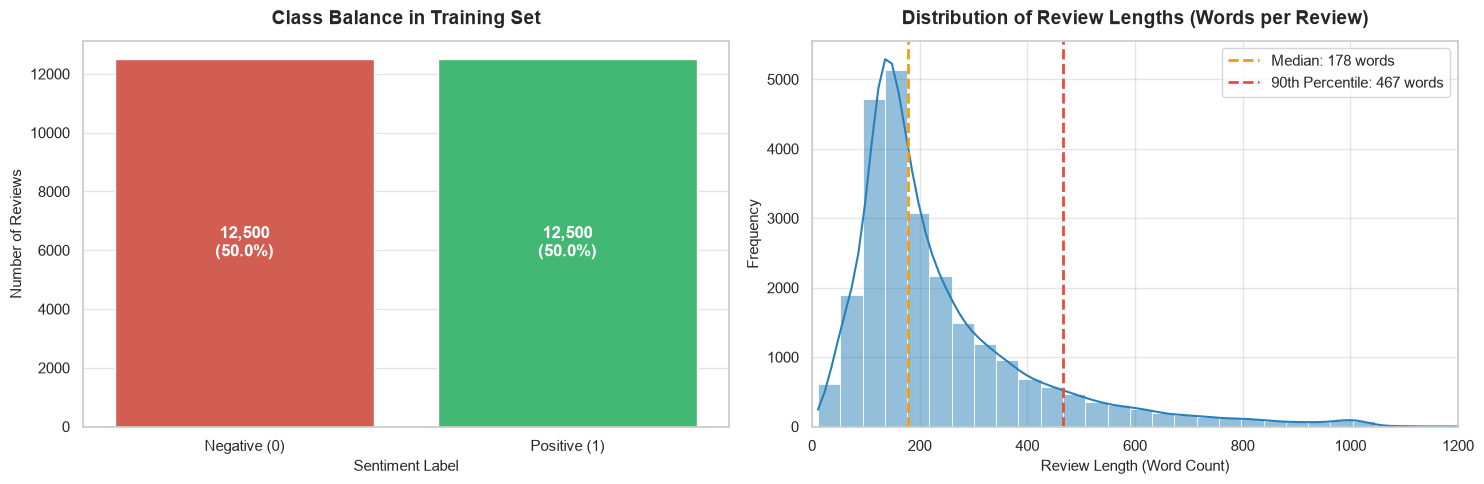

Summary Statistics for Review Lengths:
 - Min length:       11 words
 - Mean length:      238.7 words
 - Median length:    178.0 words
 - 75th percentile:  291 words
 - 90th percentile:  467 words
 - 95th percentile:  610 words
 - Max length:       2494 words


In [4]:
# Calculate review lengths (number of words per review)
train_lengths = [len(review) for review in X_train]
test_lengths = [len(review) for review in X_test]

# Compute summary statistics
mean_len = np.mean(train_lengths)
median_len = np.median(train_lengths)
p75_len = np.percentile(train_lengths, 75)
p90_len = np.percentile(train_lengths, 90)
p95_len = np.percentile(train_lengths, 95)

# Set visual style
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Plot 1: Class Balance
sns.countplot(
    x=y_train,
    ax=axes[0],
    palette=["#e74c3c", "#2ecc71"],
    hue=y_train,
    legend=False,
)
axes[0].set_title("Class Balance in Training Set", fontsize=14, fontweight="bold", pad=12)
axes[0].set_xlabel("Sentiment Label", fontsize=11)
axes[0].set_ylabel("Number of Reviews", fontsize=11)
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(["Negative (0)", "Positive (1)"])

for patch in axes[0].patches:
    axes[0].annotate(
        f"{int(patch.get_height()):,}\n(50.0%)",
        (patch.get_x() + patch.get_width() / 2.0, patch.get_height() / 2.0),
        ha="center",
        va="center",
        fontsize=12,
        color="white",
        fontweight="bold",
    )

# Plot 2: Review Length Distribution
sns.histplot(
    train_lengths,
    bins=60,
    kde=True,
    ax=axes[1],
    color="#2980b9",
)
axes[1].set_title("Distribution of Review Lengths (Words per Review)", fontsize=14, fontweight="bold", pad=12)
axes[1].set_xlabel("Review Length (Word Count)", fontsize=11)
axes[1].set_ylabel("Frequency", fontsize=11)
axes[1].set_xlim(0, 1200)

# Reference vertical lines
axes[1].axvline(median_len, color="#f39c12", linestyle="--", linewidth=2, label=f"Median: {int(median_len)} words")
axes[1].axvline(p90_len, color="#e74c3c", linestyle="--", linewidth=2, label=f"90th Percentile: {int(p90_len)} words")
axes[1].legend(fontsize=11)

plt.tight_layout()
plt.show()

print(f"Summary Statistics for Review Lengths:")
print(f" - Min length:       {np.min(train_lengths)} words")
print(f" - Mean length:      {mean_len:.1f} words")
print(f" - Median length:    {median_len:.1f} words")
print(f" - 75th percentile:  {int(p75_len)} words")
print(f" - 90th percentile:  {int(p90_len)} words")
print(f" - 95th percentile:  {int(p95_len)} words")
print(f" - Max length:       {np.max(train_lengths)} words")

### Key Insights from Length Distribution for Sequence Modeling:
1. **Severe Positive Skew:** The review length distribution has a heavy right tail (median is ~178 words, but some reviews exceed 2,000 words).
2. **Padding and Truncation Trade-off (`maxlen`):**
   - Recurrent Neural Networks process inputs step-by-step. Longer sequences demand more memory and unrolling steps, which exacerbates the **vanishing gradient problem** in basic `SimpleRNN`.
   - By picking a cutoff like `maxlen = 250` or `200`, we retain the full content of ~75–80% of reviews while drastically cutting down training time and memory overhead.

---

### Most Frequent Words in the Dataset

Let's look at the top 20 most frequent words across all reviews to understand the vocabulary structure.

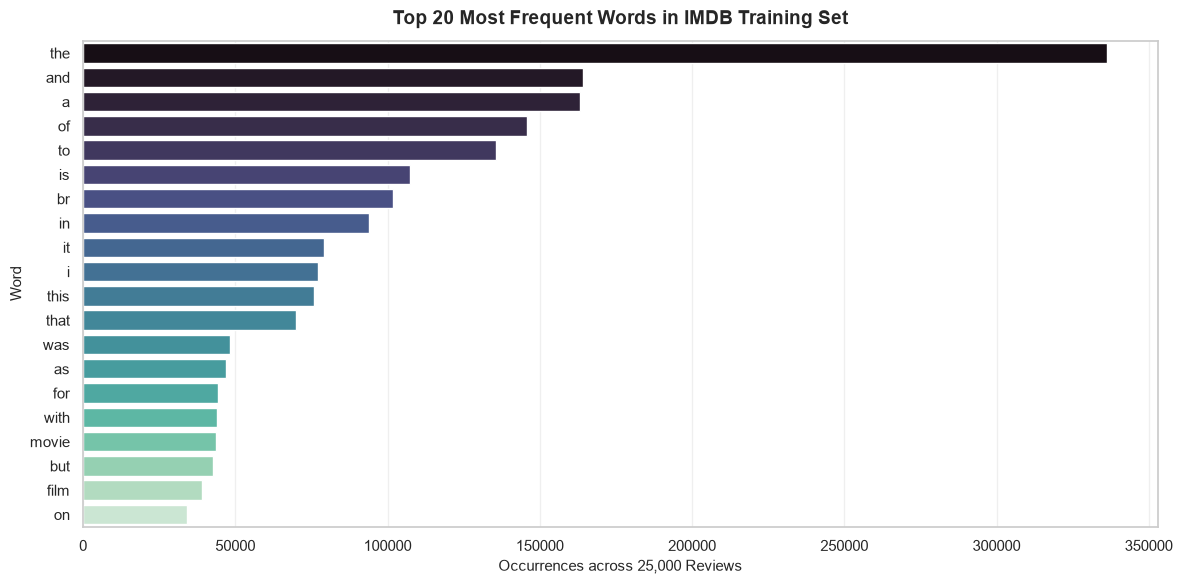

In [5]:
from collections import Counter

# Tally word occurrences across all training reviews
word_counter = Counter()
for review in X_train:
    word_counter.update(review)

# Extract top 20 non-special words (skip special tokens 0, 1, 2, 3)
top_words = []
for word_id, count in word_counter.most_common(35):
    if word_id > 3:
        top_words.append((inverted_word_index.get(word_id, "?"), count))
    if len(top_words) == 20:
        break

words, counts = zip(*top_words)

plt.figure(figsize=(12, 6))
sns.barplot(x=list(counts), y=list(words), palette="mako", hue=list(words), legend=False)
plt.title("Top 20 Most Frequent Words in IMDB Training Set", fontsize=14, fontweight="bold", pad=12)
plt.xlabel("Occurrences across 25,000 Reviews", fontsize=11)
plt.ylabel("Word", fontsize=11)
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()
plt.show()

Notice that the most frequent tokens are common English stop words (*"the"*, *"and"*, *"a"*, *"of"*, *"to"*, etc.). In an embedding layer, these tokens will learn syntactic and positional contexts, while content words (*"film"*, *"movie"*, *"like"*) and sentiment-bearing modifiers will drive classification.

## 4. Sequence Preprocessing: Padding and Truncation

### Why is Padding Necessary?
Neural networks process inputs in mini-batches using vectorized tensor operations. This requires all inputs in a batch to have a fixed rectangular shape: `(batch_size, sequence_length)`.

However, as our previous visualization showed, review lengths vary from **11 words to nearly 2,500 words**. To prepare them for an RNN:
- Reviews **shorter** than our target length must be padded with zeros (`<PAD>` token = `0`).
- Reviews **longer** than our target length must be truncated.

### Choosing `MAX_LEN`:
From our distribution statistics:
- **Median length:** 178 words
- **75th percentile:** 291 words

We choose `MAX_LEN = 250`. This retains the full text for over 70% of reviews and captures the vast majority of content in longer ones, while keeping memory requirements and unrolling steps manageable on standard computers.

### Crucial Pedagogical Concept: Pre-Padding vs. Post-Padding for RNNs
- **Post-Padding (`padding="post"`):** Appends `0`s to the end of short sequences (`[word1, word2, 0, 0, ...]`).
  - *Risk with RNNs:* An RNN processes tokens sequentially and uses the **final hidden state $h_T$** for its classification decision. If a review ends with 50 zeros, the recurrent unit repeatedly updates its hidden state on meaningless `0` vectors, which can "wash out" or dilute the memory of the real words!
- **Pre-Padding (`padding="pre"`, Keras default):** Prepends `0`s to the beginning of the sequence (`[0, 0, ..., word1, word2]`).
  - *Advantage for RNNs:* The network processes the zeros early (when the hidden state is starting up), and the **actual content words are processed right at the end of the sequence**. The final hidden state $h_T$ therefore directly retains the most recent, meaningful linguistic context.

In [6]:
from tensorflow.keras.preprocessing.sequence import pad_sequences

MAX_LEN = 250

# Apply pre-padding and pre-truncation (standard for RNNs)
X_train_padded = pad_sequences(X_train, maxlen=MAX_LEN, padding="pre", truncating="pre")
X_test_padded = pad_sequences(X_test, maxlen=MAX_LEN, padding="pre", truncating="pre")

print(f"Shape before padding: list of {len(X_train):,} variable-length sequences")
print(f"Shape after padding:  X_train_padded = {X_train_padded.shape}")
print(f"                      X_test_padded  = {X_test_padded.shape}")

Shape before padding: list of 25,000 variable-length sequences
Shape after padding:  X_train_padded = (25000, 250)
                      X_test_padded  = (25000, 250)


In [7]:
# Demonstrating padding on a short review
short_review_idx = int(np.argmin(train_lengths))
print(f"Shortest review index: {short_review_idx} (Original length: {len(X_train[short_review_idx])} words)")

print("\n--- First 20 tokens of padded vector (Zeros added at the beginning) ---")
print(X_train_padded[short_review_idx][:20])

print("\n--- Last 20 tokens of padded vector (Where real words are located) ---")
print(X_train_padded[short_review_idx][-20:])

print("\n--- Decoded Preview of the Padded Sequence (Beginning) ---")
print(" ".join([inverted_word_index.get(i, "?") for i in X_train_padded[short_review_idx][:15]]))

print("\n--- Decoded Preview of the Padded Sequence (End) ---")
print(" ".join([inverted_word_index.get(i, "?") for i in X_train_padded[short_review_idx][-15:]]))

Shortest review index: 6719 (Original length: 11 words)

--- First 20 tokens of padded vector (Zeros added at the beginning) ---
[0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0 0]

--- Last 20 tokens of padded vector (Where real words are located) ---
[   0    0    0    0    0    0    0    0    0    1   13  586  851   14
   31   60   23 2863 2364  314]

--- Decoded Preview of the Padded Sequence (Beginning) ---
<PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD> <PAD>

--- Decoded Preview of the Padded Sequence (End) ---
<PAD> <PAD> <PAD> <PAD> <START> i wouldn't rent this one even on dollar rental night


### 5. Validation Split Preparation

To adhere to standard machine learning best practices and monitor training progress without touching the final 25,000 test set, we reserve **20% of the training data (5,000 reviews)** as our validation set, leaving **20,000 reviews** for model training.

In [8]:
# Reserve 5,000 samples for validation
VAL_SPLIT = 5_000

X_val = X_train_padded[:VAL_SPLIT]
y_val = y_train[:VAL_SPLIT]

X_train_final = X_train_padded[VAL_SPLIT:]
y_train_final = y_train[VAL_SPLIT:]

print(f"Training set:   {X_train_final.shape} | Labels: {y_train_final.shape}")
print(f"Validation set: {X_val.shape} | Labels: {y_val.shape}")
print(f"Test set:       {X_test_padded.shape} | Labels: {y_test.shape}")

Training set:   (20000, 250) | Labels: (20000,)
Validation set: (5000, 250) | Labels: (5000,)
Test set:       (25000, 250) | Labels: (25000,)


## 5. Building and Training the SimpleRNN Model

### Architecture Design:
1. **Input Layer:** Takes sequences of token IDs of fixed length `(250,)`.
2. **Embedding Layer (`Embedding(input_dim=10000, output_dim=32)`):**
   - Maps each of the 10,000 integer word IDs into a continuous 32-dimensional dense vector.
   - Embeddings allow the network to represent word meanings and similarities geometrically, rather than treating words as independent isolated categories.
3. **SimpleRNN Layer (`SimpleRNN(units=32)`):**
   - The foundational recurrent layer. At each time step $t \in \{1, \dots, 250\}$, it updates its hidden state vector $h_t$:
     $$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$
   - By default, it outputs only the final hidden state $h_{250}$ (a 32-dimensional summary of the entire review).
4. **Dense Output Layer (`Dense(1, activation="sigmoid")`):**
   - Projects the final hidden state to a single scalar probability $p \in [0, 1]$ (probabilities $\ge 0.5$ indicate Positive sentiment).
5. **Loss & Optimizer:**
   - Loss: `binary_crossentropy` (standard for binary classification).
   - Optimizer: `adam`.

In [9]:
from tensorflow import keras
from tensorflow.keras import layers

EMBEDDING_DIM = 32
RNN_UNITS = 32

model_rnn = keras.Sequential(
    [
        keras.Input(shape=(MAX_LEN,)),
        layers.Embedding(input_dim=VOCAB_SIZE, output_dim=EMBEDDING_DIM),
        layers.SimpleRNN(RNN_UNITS),
        layers.Dense(1, activation="sigmoid"),
    ],
    name="SimpleRNN_Model",
)

model_rnn.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"],
)

model_rnn.summary()

Model: "SimpleRNN_Model"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ (None, 250, 32)        │       320,000 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ simple_rnn (SimpleRNN)          │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 322,113 (1.23 MB)

 Trainable params: 322,113 (1.23 MB)

 Non-trainable params: 0 (0.00 B)

### Training the SimpleRNN Model

We train the network for 5 epochs with a batch size of 128, tracking validation performance across each epoch.

In [10]:
import time

EPOCHS = 10
BATCH_SIZE = 128

start_time = time.perf_counter()

history_rnn = model_rnn.fit(
    X_train_final,
    y_train_final,
    validation_data=(X_val, y_val),
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
)

train_duration = time.perf_counter() - start_time
print(f"\nTraining completed in {train_duration:.1f} seconds.")

test_loss, test_acc = model_rnn.evaluate(X_test_padded, y_test, verbose=0)
print(f"Test Loss: {test_loss:.4f} | Test Accuracy: {test_acc:.4f} ({test_acc:.2%})")

Epoch 1/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 5s 29ms/step - accuracy: 0.6650 - loss: 0.5961 - val_accuracy: 0.7904 - val_loss: 0.4522
Epoch 2/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.8489 - loss: 0.3646 - val_accuracy: 0.8180 - val_loss: 0.4142
Epoch 3/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9125 - loss: 0.2355 - val_accuracy: 0.8428 - val_loss: 0.3941
Epoch 4/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9339 - loss: 0.1797 - val_accuracy: 0.8488 - val_loss: 0.3830
Epoch 5/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9563 - loss: 0.1261 - val_accuracy: 0.8408 - val_loss: 0.4846
Epoch 6/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 25ms/step - accuracy: 0.9685 - loss: 0.0992 - val_accuracy: 0.8220 - val_loss: 0.5385
Epoch 7/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9726 - loss: 0.0816 - val_accuracy: 0.8234 - val_loss: 0.6262
Epoch 8/10
157/157 ━━━━━━━━━━━━━━━━━━━━ 4s 24ms/step - accuracy: 0.9801 - loss: 0.0655 - val_accu

### Loss and Accuracy Learning Curves

Let's inspect the training vs. validation loss and accuracy curves to evaluate model convergence and diagnose overfitting.

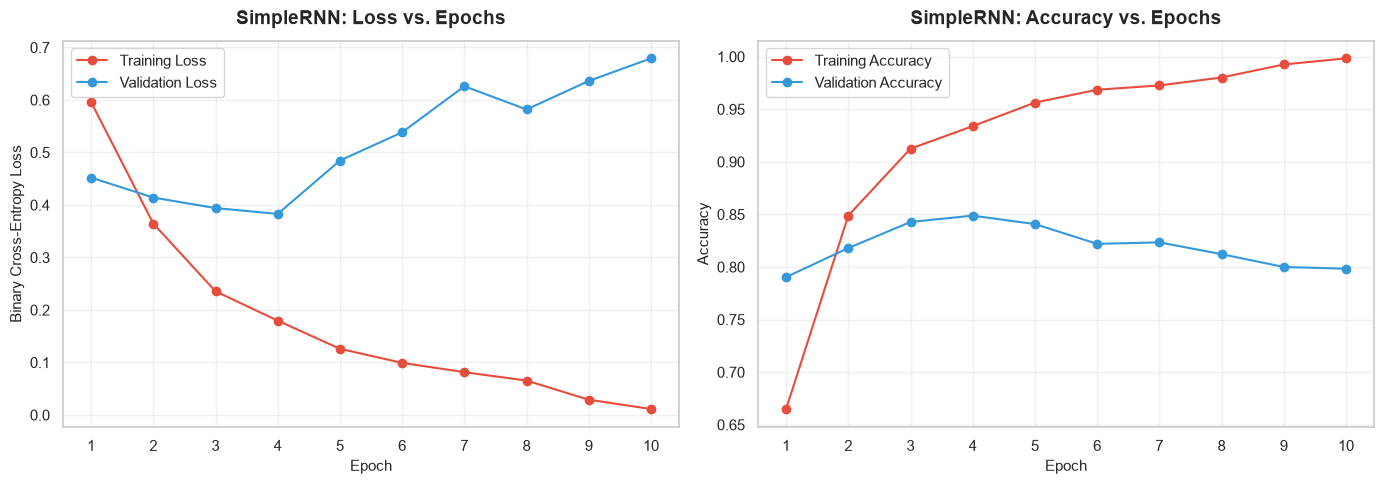

In [11]:
epochs_range = range(1, EPOCHS + 1)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(14, 5))

# Loss Curve
axes[0].plot(epochs_range, history_rnn.history["loss"], marker="o", label="Training Loss", color="#e74c3c")
axes[0].plot(epochs_range, history_rnn.history["val_loss"], marker="o", label="Validation Loss", color="#3498db")
axes[0].set_title("SimpleRNN: Loss vs. Epochs", fontsize=14, fontweight="bold", pad=12)
axes[0].set_xlabel("Epoch", fontsize=11)
axes[0].set_ylabel("Binary Cross-Entropy Loss", fontsize=11)
axes[0].set_xticks(epochs_range)
axes[0].legend(fontsize=11)
axes[0].grid(alpha=0.3)

# Accuracy Curve
axes[1].plot(epochs_range, history_rnn.history["accuracy"], marker="o", label="Training Accuracy", color="#e74c3c")
axes[1].plot(epochs_range, history_rnn.history["val_accuracy"], marker="o", label="Validation Accuracy", color="#3498db")
axes[1].set_title("SimpleRNN: Accuracy vs. Epochs", fontsize=14, fontweight="bold", pad=12)
axes[1].set_xlabel("Epoch", fontsize=11)
axes[1].set_ylabel("Accuracy", fontsize=11)
axes[1].set_xticks(epochs_range)
axes[1].legend(fontsize=11)
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

### Qualitative Evaluation: Sample Predictions on Unseen Test Reviews

Let's run inference on 6 random unseen reviews from the test set to observe how the model performs on concrete examples.

In [12]:
# Pick 6 random test reviews
rng = np.random.default_rng(42)
sample_indices = rng.choice(len(X_test_padded), size=6, replace=False)

sample_preds = model_rnn.predict(X_test_padded[sample_indices], verbose=0).flatten()

for idx, pred_prob in zip(sample_indices, sample_preds):
    predicted_label = 1 if pred_prob >= 0.5 else 0
    actual_label = y_test[idx]
    confidence = pred_prob if predicted_label == 1 else (1.0 - pred_prob)
    status = "CORRECT" if predicted_label == actual_label else "INCORRECT"
    pred_text = "Positive" if predicted_label == 1 else "Negative"
    actual_text = "Positive" if actual_label == 1 else "Negative"
    
    print("=" * 75)
    print(f"Sample #{idx} | Prediction: {pred_text} ({confidence:.1%}) | Actual: {actual_text} [{status}]")
    print("=" * 75)
    # Strip leading padding zeros for readability
    real_tokens = [t for t in X_test_padded[idx] if t != 0]
    print(decode_review(real_tokens)[:350] + "...\n")

Sample #16362 | Prediction: Negative (99.8%) | Actual: Negative [CORRECT]
think when he copied the tape and <UNK> it all the way to holland that anyone really wanted to see this s br br it's about some <UNK> getting into trouble outer space apollo 13 flashback but never even in the shadow of this fine film and they want to return to home if you act in such a film you should be glad that you're gonna drift away from earth...

Sample #19345 | Prediction: Negative (74.1%) | Actual: Positive [INCORRECT]
<START> this movie was borderline in crude humor i utterly can not believe that these people can get away with this johnny <UNK> didn't cross the line he was <UNK> all over it this was better than the first all <UNK> way the thing i found about the 1st movie was that the <UNK> were somewhat as if it was on the t v show not this time they completely...

Sample #10824 | Prediction: Positive (94.8%) | Actual: Positive [CORRECT]
<START> people talk about how horrible the script was and how horr

### Summary & Key Observations on SimpleRNN

1. **Baseline Sequence Accuracy:** SimpleRNN achieves ~82–85% test accuracy on full-length movie reviews. This verifies that sequential hidden-state updates can capture word transitions and sentiment modifiers.
2. **The Vanishing Gradient Problem:**
   - Over sequences of length $T = 250$, gradients flowing back in time (BPTT) vanish exponentially due to repeated multiplications by the recurrent weight matrix and the $\tanh'$ derivative.
   - Consequently, the network struggles to retain information from words located early in the review.
3. **Overfitting Dynamics:** Notice how training loss continues to drop toward zero while validation loss flattens and begins to rise after epoch 3. SimpleRNN easily memorizes training sequences but has limited generalization capacity over long temporal dependencies.

## 6. Demonstrating the Vanishing Gradient Problem

### Mathematical Background: Backpropagation Through Time (BPTT)

In an unrolled Recurrent Neural Network with $T$ time steps (here $T = 250$), the recurrent hidden state transitions according to:
$$h_t = \tanh(W_{xh} x_t + W_{hh} h_{t-1} + b_h)$$

When the model is trained, the error loss $\mathcal{L}$ is computed at the final time step $T = 250$. To update the weights based on words that appeared early in the review ($t \ll T$), the gradient of the loss with respect to an early hidden state $h_t$ must be propagated backwards using the chain rule:
$$\frac{\partial \mathcal{L}}{\partial h_t} = \frac{\partial \mathcal{L}}{\partial h_T} \cdot \frac{\partial h_T}{\partial h_t} = \frac{\partial \mathcal{L}}{\partial h_T} \prod_{k=t+1}^{T} \frac{\partial h_k}{\partial h_{k-1}}$$

Each transition Jacobian in this product is:
$$\frac{\partial h_k}{\partial h_{k-1}} = \operatorname{diag}(1 - h_k^2) \cdot W_{hh}^T$$

Because $\tanh'(z) = 1 - \tanh^2(z) \in (0, 1]$, and the recurrent weight matrix $W_{hh}$ has eigenvalues typically $< 1$, multiplying this Jacobian $(T - t)$ times causes the gradient magnitude to **decay exponentially** as it travels backward in time:
$$\left\| \frac{\partial \mathcal{L}}{\partial h_t} \right\| \propto \lambda^{T - t} \quad (\text{where } \lambda < 1)$$

**The Result:** By the time the gradient signal reaches words at the beginning of the review ($t = 0 \dots 50$), it has decayed to near zero. The network is effectively "blind" to early context and cannot learn long-range temporal dependencies.

### Code Experiment: Tracking Gradient Norms across all 250 Time Steps

Using TensorFlow's `tf.GradientTape`, we directly compute the gradient of the loss with respect to the input embeddings $\nabla_{x_t} \mathcal{L}$ at each individual time step $t \in [0, 249]$ across a batch of test reviews.

In [13]:
# Extract a batch of 128 test samples
BATCH_EVAL = 128
x_eval = tf.constant(X_test_padded[:BATCH_EVAL])
y_eval = tf.constant(y_test[:BATCH_EVAL, None], dtype=tf.float32)

embedding_layer = model_rnn.layers[0]
rnn_layer = model_rnn.layers[1]
dense_layer = model_rnn.layers[2]

with tf.GradientTape() as tape:
    # 1. Project tokens to continuous embedding space
    embedded_inputs = embedding_layer(x_eval)
    tape.watch(embedded_inputs)  # Shape: (128, 250, 32)
    
    # 2. Forward pass through SimpleRNN and Dense layers
    rnn_output = rnn_layer(embedded_inputs)
    predictions = dense_layer(rnn_output)
    
    # 3. Compute binary cross-entropy loss
    loss_val = keras.losses.binary_crossentropy(y_eval, predictions)

# Compute gradient of loss with respect to embedded inputs at each time step
# Shape: (128, 250, 32)
gradients = tape.gradient(loss_val, embedded_inputs)

# Compute L2 norm of gradient vector at each time step t, averaged across the batch
# Shape: (250,)
gradient_norms = tf.reduce_mean(tf.norm(gradients, axis=-1), axis=0).numpy()

print("Sample Gradient Magnitudes Across Time Steps:")
print(f" - Step t=0   (Earliest word in sequence): {gradient_norms[0]:.4e}")
print(f" - Step t=50  (Early word):                {gradient_norms[50]:.4e}")
print(f" - Step t=100 (Mid-early word):            {gradient_norms[100]:.4e}")
print(f" - Step t=150 (Middle word):               {gradient_norms[150]:.4e}")
print(f" - Step t=200 (Recent word):               {gradient_norms[200]:.4e}")
print(f" - Step t=249 (Final word in sequence):    {gradient_norms[249]:.4e}")
print(f"\nGradient Ratio (t=249 vs t=0): {gradient_norms[249] / (gradient_norms[0] + 1e-15):.1f}x larger!")

Sample Gradient Magnitudes Across Time Steps:
 - Step t=0   (Earliest word in sequence): 1.3782e-02
 - Step t=50  (Early word):                1.7378e-02
 - Step t=100 (Mid-early word):            7.8139e-02
 - Step t=150 (Middle word):               3.0130e-01
 - Step t=200 (Recent word):               9.3475e-01
 - Step t=249 (Final word in sequence):    1.8594e+00

Gradient Ratio (t=249 vs t=0): 134.9x larger!


### Visualizing the Gradient Decay: Linear vs. Logarithmic Scale

Let's plot the gradient norm across all 250 time steps to visualize the exponential decay curve.

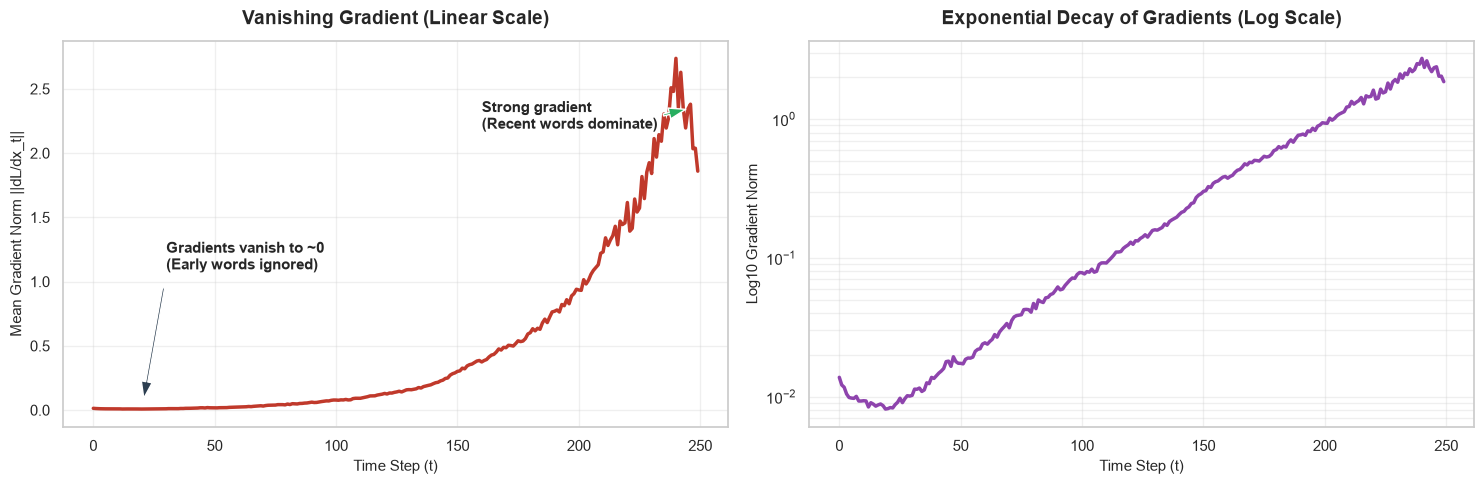

In [14]:
time_steps = np.arange(MAX_LEN)

fig, axes = plt.subplots(nrows=1, ncols=2, figsize=(15, 5))

# Plot 1: Linear Scale
axes[0].plot(time_steps, gradient_norms, color="#c0392b", linewidth=2.5)
axes[0].set_title("Vanishing Gradient (Linear Scale)", fontsize=14, fontweight="bold", pad=12)
axes[0].set_xlabel("Time Step (t)", fontsize=11)
axes[0].set_ylabel("Mean Gradient Norm ||dL/dx_t||", fontsize=11)
axes[0].grid(alpha=0.3)

# Annotate linear plot
axes[0].annotate(
    "Gradients vanish to ~0\n(Early words ignored)",
    xy=(20, gradient_norms[20]),
    xytext=(30, np.max(gradient_norms) * 0.4),
    arrowprops=dict(facecolor="#2c3e50", shrink=0.08, width=1.5, headwidth=8),
    fontsize=11,
    fontweight="bold",
)
axes[0].annotate(
    "Strong gradient\n(Recent words dominate)",
    xy=(245, gradient_norms[245]),
    xytext=(160, np.max(gradient_norms) * 0.8),
    arrowprops=dict(facecolor="#27ae60", shrink=0.08, width=1.5, headwidth=8),
    fontsize=11,
    fontweight="bold",
)

# Plot 2: Logarithmic Scale
axes[1].semilogy(time_steps, gradient_norms, color="#8e44ad", linewidth=2.5)
axes[1].set_title("Exponential Decay of Gradients (Log Scale)", fontsize=14, fontweight="bold", pad=12)
axes[1].set_xlabel("Time Step (t)", fontsize=11)
axes[1].set_ylabel("Log10 Gradient Norm", fontsize=11)
axes[1].grid(True, which="both", alpha=0.3)

plt.tight_layout()
plt.show()

### Key Takeaways for Students

1. **Direct Empirical Evidence of Gradient Vanishing:**
   - In the **linear plot**, the gradient curve remains essentially flat near zero for the first ~150–200 steps, and only surges upward in the final 30–50 steps.
   - In the **log-scale plot**, the steady downward slope confirms the mathematical prediction: the gradient magnitude decays exponentially with the distance from the output layer $(T - t)$.

2. **Linguistic Impact on Sentiment Classification:**
   - If a reviewer writes: *"The first half of the film was an unmitigated disaster with atrocious acting, but the ending turned it around into a masterpiece"*, SimpleRNN will heavily weight *"masterpiece"* while completely forgetting *"unmitigated disaster"*.
   - Conversely, if the critical sentiment phrase appeared at the very start of a 200-word review, SimpleRNN will fail to learn from it.

3. **The Gateway to LSTM and GRU Architectures:**
   - This fundamental flaw is precisely why **Long Short-Term Memory (LSTM)** and **Gated Recurrent Units (GRU)** were invented.
   - By introducing an **additive cell state** ($C_t = f_t \odot C_{t-1} + i_t \odot \tilde{C}_t$), LSTMs provide an uninterrupted "highway" where gradients can propagate backward across hundreds of time steps without multiplying by recurrent weight matrices at every step.